In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
df = pd.read_csv("messy_house_data.csv").copy()

In [3]:
df

,house_id,city,area_sqft,bedrooms,age_years,price_lakhs,furnishing,agent_rating,listing_date
0,1085,Hyderabad,1733.0,3,24,65.2,Unfurnished,3.7,2024-07-09
1,1456,Hyderabad,882.0,1,14,25.3,Furnished,4.0,2025-04-27
2,1363,Hyderabad,1358.0,2,11,55.7,Unfurnished,2.9,2025-08-11
3,1379,Bangalore,1700.0,3,15,87.4,Semi-Furnished,4.9,2025-01-01
4,1078,Chennai,840.0,2,26,15.0,Furnished,2.9,2024-09-02
...,...,...,...,...,...,...,...,...,...
513,1076,Hyderabad,NaN,2,19,33.9,Furnished,4.4,2024-09-24
514,1467,Chennai,450.0,2,1,18.7,Unfurnished,3.9,2024-04-05
515,1300,Chennai,1377.0,3,9,34.8,NaN,3.0,2024-08-06
516,1494,Hyd,950.0,2,2,43.4,Unfurnished,4.4,2025-02-26


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 518 entries, 0 to 517
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   house_id      518 non-null    int64  
 1   city          450 non-null    object 
 2   area_sqft     476 non-null    float64
 3   bedrooms      518 non-null    int64  
 4   age_years     518 non-null    int64  
 5   price_lakhs   493 non-null    object 
 6   furnishing    498 non-null    object 
 7   agent_rating  488 non-null    float64
 8   listing_date  518 non-null    object 
dtypes: float64(2), int64(3), object(4)
memory usage: 36.6+ KB


In [5]:
df.describe()

,house_id,area_sqft,bedrooms,age_years,agent_rating
count,518.000000,476.000000,518.000000,518.000000,488.000000
mean,1250.119691,2300.512605,2.610039,15.131274,3.816189
std,144.478911,14467.780367,1.307047,13.880610,1.011639
min,1001.000000,0.000000,0.000000,-5.000000,-1.000000
25%,1124.250000,1078.250000,2.000000,7.000000,3.100000
50%,1250.500000,1409.500000,3.000000,14.000000,3.800000
75%,1373.750000,1678.750000,3.000000,23.000000,4.400000
max,1500.000000,300000.000000,15.000000,200.000000,11.000000


In [6]:
df.head()

,house_id,city,area_sqft,bedrooms,age_years,price_lakhs,furnishing,agent_rating,listing_date
0,1085,Hyderabad,1733.0,3,24,65.2,Unfurnished,3.7,2024-07-09
1,1456,Hyderabad,882.0,1,14,25.3,Furnished,4.0,2025-04-27
2,1363,Hyderabad,1358.0,2,11,55.7,Unfurnished,2.9,2025-08-11
3,1379,Bangalore,1700.0,3,15,87.4,Semi-Furnished,4.9,2025-01-01
4,1078,Chennai,840.0,2,26,15.0,Furnished,2.9,2024-09-02


In [7]:
df.tail()

,house_id,city,area_sqft,bedrooms,age_years,price_lakhs,furnishing,agent_rating,listing_date
513,1076,Hyderabad,NaN,2,19,33.9,Furnished,4.4,2024-09-24
514,1467,Chennai,450.0,2,1,18.7,Unfurnished,3.9,2024-04-05
515,1300,Chennai,1377.0,3,9,34.8,NaN,3.0,2024-08-06
516,1494,Hyd,950.0,2,2,43.4,Unfurnished,4.4,2025-02-26
517,1169,Bangalore,1224.0,3,28,37.2,Furnished,4.5,2024-08-13


In [10]:
df.isnull().sum()

house_id         0
city            68
area_sqft       42
bedrooms         0
age_years        0
price_lakhs     25
furnishing      20
agent_rating    30
listing_date     0
dtype: int64

In [18]:
df["city"]

0       True
1       True
2       True
3      False
4      False
       ...  
513     True
514    False
515    False
516    False
517    False
Name: city, Length: 518, dtype: object

In [20]:
df.groupby("city")["house_id"].count()

city
Bangalore      89
Bengaluru      27
Chennai        61
Chennai         1
Hyd            29
Hyderabad     123
Hyderabad       1
Mumbai         58
Pune           53
bangalore       6
chennai         1
hyderabad       1
Name: house_id, dtype: int64

In [21]:
df["city"] = df["city"].str.lower()

In [22]:
df.groupby("city")["house_id"].count()

city
bangalore      95
bengaluru      27
chennai        62
chennai         1
hyd            29
hyderabad     124
hyderabad       1
mumbai         58
pune           53
Name: house_id, dtype: int64

In [29]:
cities = {"hyd":"hyderabad","bengaluru":"bangalore","chennai":"chennai","hyderabad":"hyderabad"}
df["city"] = df["city"].replace(cities).copy()

In [30]:
df.groupby("city")["house_id"].count()

city
bangalore     122
chennai        62
chennai         1
hyderabad     153
hyderabad       1
mumbai         58
pune           53
Name: house_id, dtype: int64

In [37]:
df["city"].isnull().sum()

np.int64(68)

In [47]:
df["city"] = df["city"].fillna(df["city"].mode()[0])

In [48]:
df.isnull().sum()

house_id         0
city             0
area_sqft       42
bedrooms         0
age_years        0
price_lakhs     25
furnishing      20
agent_rating    30
listing_date     0
dtype: int64

In [46]:
df["city"].mode()[0]

'hyderabad'

In [54]:
df["area_sqft"] = df["area_sqft"].fillna(df["area_sqft"].mean())

In [55]:
df.isnull().sum()

house_id         0
city             0
area_sqft        0
bedrooms         0
age_years        0
price_lakhs     25
furnishing      20
agent_rating    30
listing_date     0
dtype: int64

In [56]:
df

,house_id,city,area_sqft,bedrooms,age_years,price_lakhs,furnishing,agent_rating,listing_date
0,1085,hyderabad,1733.000000,3,24,65.2,Unfurnished,3.7,2024-07-09
1,1456,hyderabad,882.000000,1,14,25.3,Furnished,4.0,2025-04-27
2,1363,hyderabad,1358.000000,2,11,55.7,Unfurnished,2.9,2025-08-11
3,1379,bangalore,1700.000000,3,15,87.4,Semi-Furnished,4.9,2025-01-01
4,1078,chennai,840.000000,2,26,15.0,Furnished,2.9,2024-09-02
...,...,...,...,...,...,...,...,...,...
513,1076,hyderabad,2300.512605,2,19,33.9,Furnished,4.4,2024-09-24
514,1467,chennai,450.000000,2,1,18.7,Unfurnished,3.9,2024-04-05
515,1300,chennai,1377.000000,3,9,34.8,NaN,3.0,2024-08-06
516,1494,hyderabad,950.000000,2,2,43.4,Unfurnished,4.4,2025-02-26


In [59]:
df = df.dropna(subset="price_lakhs").copy()

In [62]:
df.groupby("furnishing")["house_id"].count()

furnishing
Furnished         169
Semi-Furnished    137
Unfurnished       168
Name: house_id, dtype: int64

In [65]:
df["furnishing"] = df["furnishing"].fillna(df["furnishing"].mode()[0]).copy()

In [66]:
df.isnull().sum()

house_id         0
city             0
area_sqft        0
bedrooms         0
age_years        0
price_lakhs      0
furnishing       0
agent_rating    30
listing_date     0
dtype: int64

In [67]:
df["agent_rating"] = df["agent_rating"].fillna(df["agent_rating"].mean()).copy()

In [70]:
df.isnull().sum()

house_id        0
city            0
area_sqft       0
bedrooms        0
age_years       0
price_lakhs     0
furnishing      0
agent_rating    0
listing_date    0
dtype: int64

In [73]:
df["listing_date"] = pd.to_datetime(df["listing_date"] ,format="%Y-%m-%d" , errors="coerce").copy()

In [74]:
df

,house_id,city,area_sqft,bedrooms,age_years,price_lakhs,furnishing,agent_rating,listing_date
0,1085,hyderabad,1733.000000,3,24,65.2,Unfurnished,3.7,2024-07-09
1,1456,hyderabad,882.000000,1,14,25.3,Furnished,4.0,2025-04-27
2,1363,hyderabad,1358.000000,2,11,55.7,Unfurnished,2.9,2025-08-11
3,1379,bangalore,1700.000000,3,15,87.4,Semi-Furnished,4.9,2025-01-01
4,1078,chennai,840.000000,2,26,15.0,Furnished,2.9,2024-09-02
...,...,...,...,...,...,...,...,...,...
513,1076,hyderabad,2300.512605,2,19,33.9,Furnished,4.4,2024-09-24
514,1467,chennai,450.000000,2,1,18.7,Unfurnished,3.9,2024-04-05
515,1300,chennai,1377.000000,3,9,34.8,Furnished,3.0,2024-08-06
516,1494,hyderabad,950.000000,2,2,43.4,Unfurnished,4.4,2025-02-26


In [96]:
no_of_houses = df.groupby("city")["house_id"].count().values
cities = df.groupby("city")["house_id"].count().index

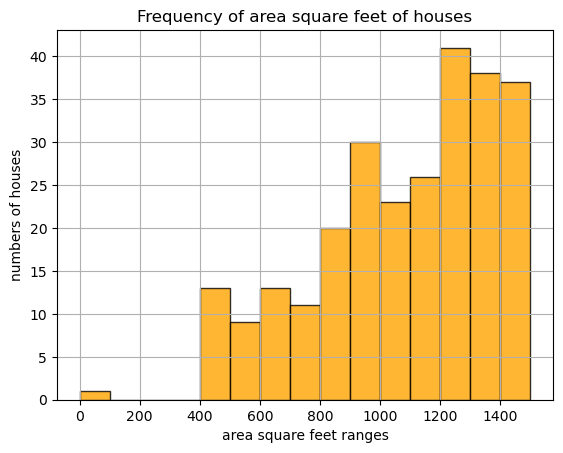

In [88]:
#area_sqft ranges

plt.hist(df["area_sqft"],bins=[0,100,200,300,400,500,600,700,800,900,1000,1100,1200,1300,1400,1500],
         edgecolor="black",color="orange",alpha=0.8)
plt.xlabel("area square feet ranges")
plt.ylabel("numbers of houses")
plt.title("Frequency of area square feet of houses")
plt.grid(True)
plt.show()

#there are more houses with area square feets between 1200 - 1300 

In [101]:
df["city"] = df["city"].str.strip().str.lower()


In [103]:
no_of_houses = df.groupby("city")["house_id"].count().values
cities = df.groupby("city")["house_id"].count().index

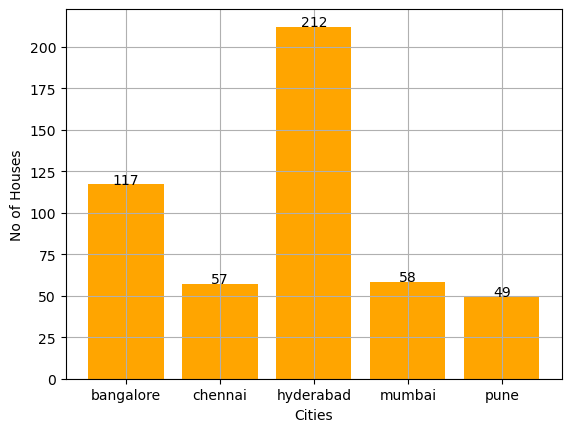

In [112]:
plt.bar(cities,no_of_houses,color="orange")

for i in range(len(cities)):
    plt.text(i,no_of_houses[i]+0.5,str(no_of_houses[i]),ha="center")

plt.xlabel("Cities")
plt.ylabel("No of Houses")
plt.grid(True)
plt.show()

#hyderabad city have more number of house compare to other cities 